# AES


## Основные преобразования

In [ ]:
sb = [0x63, 0x7c, 0x77, 0x7b, 0xf2, 0x6b, 0x6f, 0xc5, 0x30, 0x01, 0x67, 0x2b, 0xfe, 0xd7, 0xab, 0x76,
      0xca, 0x82, 0xc9, 0x7d, 0xfa, 0x59, 0x47, 0xf0, 0xad, 0xd4, 0xa2, 0xaf, 0x9c, 0xa4, 0x72, 0xc0,
      0xb7, 0xfd, 0x93, 0x26, 0x36, 0x3f, 0xf7, 0xcc, 0x34, 0xa5, 0xe5, 0xf1, 0x71, 0xd8, 0x31, 0x15,
      0x04, 0xc7, 0x23, 0xc3, 0x18, 0x96, 0x05, 0x9a, 0x07, 0x12, 0x80, 0xe2, 0xeb, 0x27, 0xb2, 0x75,
      0x09, 0x83, 0x2c, 0x1a, 0x1b, 0x6e, 0x5a, 0xa0, 0x52, 0x3b, 0xd6, 0xb3, 0x29, 0xe3, 0x2f, 0x84,
      0x53, 0xd1, 0x00, 0xed, 0x20, 0xfc, 0xb1, 0x5b, 0x6a, 0xcb, 0xbe, 0x39, 0x4a, 0x4c, 0x58, 0xcf,
      0xd0, 0xef, 0xaa, 0xfb, 0x43, 0x4d, 0x33, 0x85, 0x45, 0xf9, 0x02, 0x7f, 0x50, 0x3c, 0x9f, 0xa8,
      0x51, 0xa3, 0x40, 0x8f, 0x92, 0x9d, 0x38, 0xf5, 0xbc, 0xb6, 0xda, 0x21, 0x10, 0xff, 0xf3, 0xd2,
      0xcd, 0x0c, 0x13, 0xec, 0x5f, 0x97, 0x44, 0x17, 0xc4, 0xa7, 0x7e, 0x3d, 0x64, 0x5d, 0x19, 0x73,
      0x60, 0x81, 0x4f, 0xdc, 0x22, 0x2a, 0x90, 0x88, 0x46, 0xee, 0xb8, 0x14, 0xde, 0x5e, 0x0b, 0xdb,
      0xe0, 0x32, 0x3a, 0x0a, 0x49, 0x06, 0x24, 0x5c, 0xc2, 0xd3, 0xac, 0x62, 0x91, 0x95, 0xe4, 0x79,
      0xe7, 0xc8, 0x37, 0x6d, 0x8d, 0xd5, 0x4e, 0xa9, 0x6c, 0x56, 0xf4, 0xea, 0x65, 0x7a, 0xae, 0x08,
      0xba, 0x78, 0x25, 0x2e, 0x1c, 0xa6, 0xb4, 0xc6, 0xe8, 0xdd, 0x74, 0x1f, 0x4b, 0xbd, 0x8b, 0x8a,
      0x70, 0x3e, 0xb5, 0x66, 0x48, 0x03, 0xf6, 0x0e, 0x61, 0x35, 0x57, 0xb9, 0x86, 0xc1, 0x1d, 0x9e,
      0xe1, 0xf8, 0x98, 0x11, 0x69, 0xd9, 0x8e, 0x94, 0x9b, 0x1e, 0x87, 0xe9, 0xce, 0x55, 0x28, 0xdf,
      0x8c, 0xa1, 0x89, 0x0d, 0xbf, 0xe6, 0x42, 0x68, 0x41, 0x99, 0x2d, 0x0f, 0xb0, 0x54, 0xbb, 0x16
     ]


def SB(bytes_string: bytes) -> bytes:
    return bytes([sb[byte] for byte in bytes_string])

def invSB(bytes_string: bytes) -> bytes:
    return bytes([sb.index(byte) for byte in bytes_string])

def SR(bytes_string: bytes) -> bytes:
    result = bytes_string[:4]
    for i in range(1, 4):
        # print(bytes_string[4*i:5*i], bytes_string[5*i:4*(i+1)])
        result += bytes_string[5*i:4*(i+1)] + bytes_string[4*i:5*i]
    return result

def invSR(bytes_string: bytes) -> bytes:
    result = bytes_string[:4]
    for i in range(2, 5):
        # print(bytes_string[4*i:5*i], bytes_string[5*i:4*(i+1)])
        result += bytes_string[3*i+1:4*i] + bytes_string[4*(i-1):3*i+1]
    return result

def mul_2(num: int) -> int:
    num <<= 1
    if num.bit_length() > 8:
        num ^= 0x11b
    return num

def mul(a: int, b: int) -> int:
    result = 0
    while b:
        if b & 1:
            result ^= a
        a = mul_2(a)
        b >>= 1
    return result

def MC(bytes_string: bytes) -> bytes:
    c = [[2, 3, 1, 1],
         [1, 2, 3, 1],
         [1, 1, 2, 3],
         [3, 1, 1, 2]]
    result = b''
    for i in c:
        for j in range(4):
            d = 0
            for k in range(4):
                d ^= mul(i[k], bytes_string[k*4+j])
            result += bytes([d])
    return result

def invMC(bytes_string: bytes) -> bytes:
    c = [[0xe, 0xb, 0xd, 0x9],
         [0x9, 0xe, 0xb, 0xd],
         [0xd, 0x9, 0xe, 0xb],
         [0xb, 0xd, 0x9, 0xe]]
    result = b''
    for i in c:
        for j in range(4):
            d = 0
            for k in range(4):
                d ^= mul(i[k], bytes_string[k*4+j])
            result += bytes([d])
    return result

def xor(bytes_string: bytes, key: list[bytes]) -> bytes:
    return bytes([element ^ key[i % 4][i // 4] for i, element in enumerate(bytes_string)])




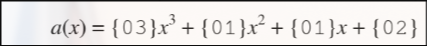

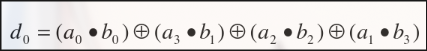

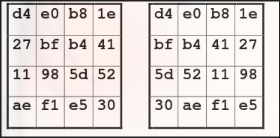



## Развёртка ключа

In [ ]:
RC = [1]
for i in range(9):
    RC.append(mul_2(RC[i]))
print(RC)
def R(i: int) -> bytes:
    return bytes([RC[i], 0, 0, 0])

def rot(w: bytes) -> bytes:
    return w[1:] + w[0:1]

def g(w: bytes, i: int) -> bytes:
    after_SB_key = SB(rot(w))
    return bytes([R(i)[0] ^ after_SB_key[0]]) + after_SB_key[1:]

def key_gen(key: bytes):
    W = [key[4 * i: 4 * (i + 1)] for i in range(4)]
    for i in range(10):
        w_i = bytes([a ^ b for a, b in zip(W[-4], g(W[-1], i))])
        W.append(w_i)
        for j in range(3):
            w_ij = bytes([a ^ b for a, b in zip(W[-4], W[-1])])
            W.append(w_ij)
    return W




In [ ]:
def text_transform(bytes_string: bytes) -> bytes:
    table = bytes()
    for i in range(4):
        for j in range(4):
            table += bytes([bytes_string[j*4+i]])
    return table



def AES_encrypt_block(bytes_string: bytes, key: bytes) -> bytes:
    bytes_string = text_transform(bytes_string)
    key_extend = key_gen(key)
    bytes_string = xor(bytes_string, key_extend[0:4])
    for i in range(1, 10):
        bytes_string = xor(MC(SR(SB(bytes_string))), key_extend[4 * i:4 * (i + 1)])

    bytes_string = xor(SR(SB(bytes_string)), key_extend[-4:])
    return text_transform(bytes_string)

def AES_decrypt_block(bytes_string: bytes, key: bytes) -> bytes:
    bytes_string = text_transform(bytes_string)
    key_extend = key_gen(key)
    bytes_string = xor(bytes_string, key_extend[-4:])

    bytes_string = xor(invSB(invSR(bytes_string)), key_extend[-8:-4])
    for i in range(2, 11):
        bytes_string = xor(invSB(invSR(invMC(bytes_string))), key_extend[-4 * (i+1):-4 * i])
    return text_transform(bytes_string)


key = b'\x2b\x7e\x15\x16\x28\xae\xd2\xa6\xab\xf7\x15\x88\x09\xcf\x4f\x3c'
text = b'\x32\x43\xf6\xa8\x88\x5a\x30\x8d\x31\x31\x98\xa2\xe0\x37\x07\x34'
ct = AES_encrypt_block(text, key)
check_text = AES_decrypt_block(ct, key)
print(ct.hex())
print(check_text == text)
print(key.hex())
print(text.hex())

## Шифрование и расшифрование